In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:

# 1. Dynamically locate the folder where this script/notebook is running
try:
    script_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
# Notebook environment fallback (works for VS Code Notebooks & Jupyter)
    script_dir = os.getcwd()

# 2. Point to the CSV file inside your repository folder
target_path = os.path.join(script_dir, "Advertising Budget and Sales.csv")

try:
    df = pd.read_csv(target_path)
    print(f"Dataset successfully loaded from repo path: {target_path}")

    # Fix: Check if the file loaded without text headers
    first_col_name = str(df.columns)
    if (
        first_col_name.replace(".", "", 1).isdigit()
        or "Unnamed" in first_col_name
        or len(df.columns) >= 4
    ):
        print("No text headers detected. Forcing column assignments...")
        if len(df.columns) == 5:
            df.columns = ["Index", "TV", "Radio", "Newspaper", "Sales"]
        elif len(df.columns) == 4:
            df.columns = ["TV", "Radio", "Newspaper", "Sales"]

except FileNotFoundError:
    print(f"File not found at {target_path}. Generating fallback sample data...")
    np.random.seed(42)
    n_samples = 200
    tv = np.random.uniform(10, 300, n_samples)
    radio = np.random.uniform(5, 50, n_samples)
    newspaper = np.random.uniform(2, 100, n_samples)
    sales = (
        5
        + 0.05 * tv
        + 0.18 * radio
        + 0.003 * newspaper
        + np.random.normal(0, 2, n_samples)
    )
    df = pd.DataFrame(
        {"TV": tv, "Radio": radio, "Newspaper": newspaper, "Sales": sales}
    )

# Strip out any remaining indexing columns (Kaggle artifacts)
df = df.loc[:, ~df.columns.str.contains("^Unnamed|^Index", case=False)]

print("\n--- [By Vedansh] Cleaned Dataset Overview ---")
print(df.head())


X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

Dataset successfully loaded from repo path: c:\Users\HP\Downloads\Mini-Project-Group-76-main (1)\Mini-Project-Group-76-main\Advertising Budget and Sales.csv
No text headers detected. Forcing column assignments...

--- [By Vedansh] Cleaned Dataset Overview ---
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


In [3]:
from sklearn.model_selection import train_test_split

"""Splits features into test environments and trains a multi-linear model."""
# Split into Training and Testing Sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

In [4]:
# Check for missing values (NaNs) across all columns
print("Missing values per column:\n", df.isnull().sum())

# Check data types to see if any columns are text/objects instead of numbers
print("\nColumn data types:\n", df.dtypes)

Missing values per column:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Column data types:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

# Replace NaN values with the median value of that column
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Convert arrays back to DataFrames temporarily just to keep column tracking clean
X_train_imputed_df = pd.DataFrame(X_train_imputed, columns=X.columns)
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X.columns)

# Initialize the selector to find the top 3 features based on training labels
selector = SelectKBest(score_func=f_regression, k=3)

# Learn which 3 features are best from the training set, and drop the rest
X_train_selected = selector.fit_transform(X_train_imputed_df, y_train)

# Drop the irrelevant features from the test set using the exact same choices
X_test_selected = selector.transform(X_test_imputed_df)

selected_features = X.columns[selector.get_support()].tolist()
print("Features selected for training:", selected_features)

# Fit the scaler ONLY on training data, then transform both subsets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

# Initialize and Train
model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("Model trained")

Features selected for training: ['TV', 'Radio', 'Newspaper']
Model trained


In [7]:
# Identify categorical columns dynamically (if any exist)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if len(categorical_cols) > 0:
    print(f"Encoding categorical columns: {categorical_cols}")
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
else:
    print("No categorical columns found. Dummy encoding is not required for this numerical dataset.")
    df_encoded = df.copy()

No categorical columns found. Dummy encoding is not required for this numerical dataset.


In [8]:
# Computes Pearson correlation and sorts features by their relationship with the target variable
correlation_matrix = df.corr()
print("Correlation with Target:\n", correlation_matrix['Sales'].sort_values(ascending=False))
print("\n--- [By Deepanshu] Model training complete ---")

Correlation with Target:
 Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64

--- [By Deepanshu] Model training complete ---


In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error

"""Calculates statistical errors and benchmarks custom values."""
y_pred = model.predict(X_test_scaled)

# Calculate operational metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# --- THE FIX: Convert continuous values to whole-number binary classes ---
# This sets the median value as the boundary. Higher than median = 1, Lower = 0.
cutoff = np.median(y_test)
y_test_class = (y_test > cutoff).astype(int)
y_pred_class = (y_pred > cutoff).astype(int)

# Use the converted classes in your metrics
confusem = confusion_matrix(y_test_class, y_pred_class)
accuracy = accuracy_score(y_test_class, y_pred_class)
precision = precision_score(y_test_class, y_pred_class, zero_division=0)
recall = recall_score(y_test_class, y_pred_class, zero_division=0)
f1 = f1_score(y_test_class, y_pred_class, zero_division=0)
rmse = np.sqrt(mse)                     # Root Mean Squared Error
mae = mean_absolute_error(y_test, y_pred) # Mean Absolute Error

print("\n--- [Srivarsha] Model Evaluation ---")

print("--- Classification Evaluation Metrics ---")
print(f"Confusion Matrix:\n{confusem}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared Score (R²): {r2:.4f}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"Coefficients (TV, Radio, Newspaper): {model.coef_}")

# Run a custom production value prediction
# Budget matrix format: [[TV_Budget, Radio_Budget, Newspaper_Budget]]
custom_budget = np.array([[200.0, 30.0, 15.0]])

# Clean it, truncate it down to the selected 3 features, and normalize it
custom_imputed = imputer.transform(custom_budget)
custom_selected = selector.transform(custom_imputed)
custom_scaled = scaler.transform(custom_selected)
custom_pred = model.predict(custom_scaled)
print(
f"\nInference Prediction (TV:200, Radio:30, Newspaper:15) -> Estimated Sales: {custom_pred[0]:.4f}"
)


--- [Srivarsha] Model Evaluation ---
--- Classification Evaluation Metrics ---
Confusion Matrix:
[[14  6]
 [ 1 19]]
Accuracy:  0.8250
Precision: 0.7600
Recall:    0.9500
F1 Score:  0.8444
Root Mean Squared Error (RMSE): 1.7816
Mean Absolute Error (MAE):      1.4608
Mean Squared Error (MSE): 3.1741
R-squared Score (R²): 0.8994
Intercept: 14.1000
Coefficients (TV, Radio, Newspaper): [3.76419618 2.79230665 0.05597551]

Inference Prediction (TV:200, Radio:30, Newspaper:15) -> Estimated Sales: 17.6422


c:\Users\HP\miniconda3\envs\ai101\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\HP\miniconda3\envs\ai101\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SelectKBest was fitted with feature names
  warnings.warn(


In [10]:
def plot_insights(df, y_test, y_pred):
    """Generates analytical charts for budget trends and predictive accuracy."""
    print("\n--- [Jatin] Launching UI Visualization Panels ---")
    plt.figure(figsize=(15, 5))

    # Feature correlation versus target
    features = ["TV", "Radio", "Newspaper"]
    for i, feature in enumerate(features, 1):
        plt.subplot(1, 3, i)
        plt.scatter(df[feature], df["Sales"], color="royalblue", alpha=0.6)
        plt.title(f"{feature} Budget vs Sales")
        plt.xlabel(f"{feature} Budget")
        plt.ylabel("Sales")
        plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Model deviation map
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred, color="forestgreen", alpha=0.7, edgecolors="k")
    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--",
        lw=2,
        label="Perfect Prediction Line",
    )
    plt.title("Actual vs Predicted Sales")
    plt.xlabel("Actual Sales")
    plt.ylabel("Predicted Sales")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()


c:\Users\HP\miniconda3\envs\ai101\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(



--- [Jatin] Launching UI Visualization Panels ---


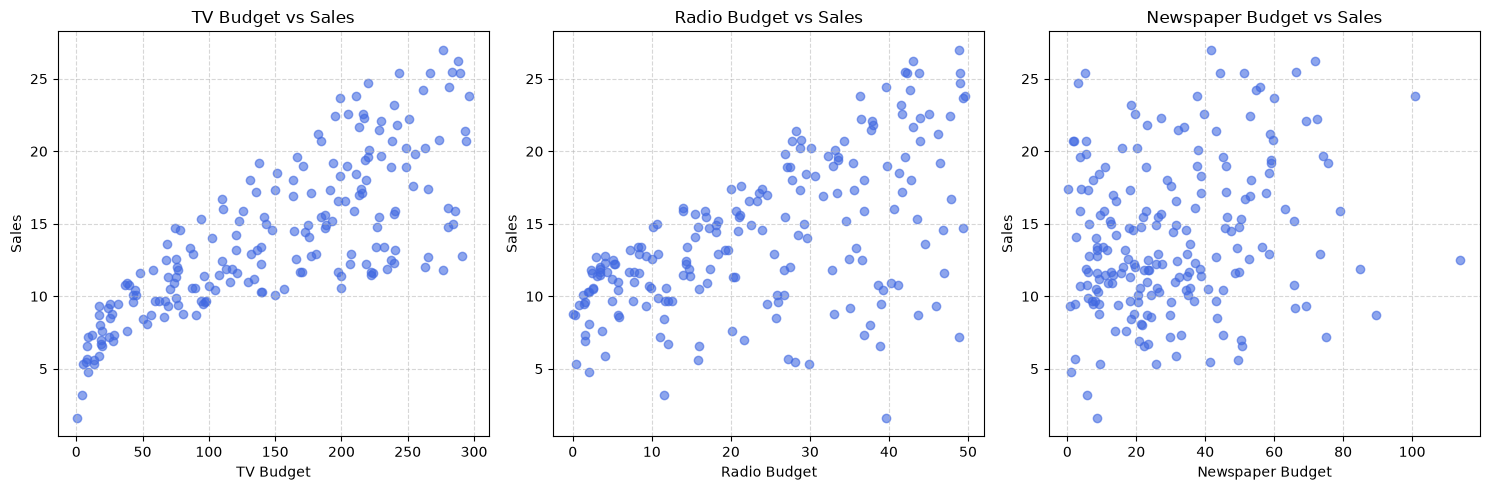

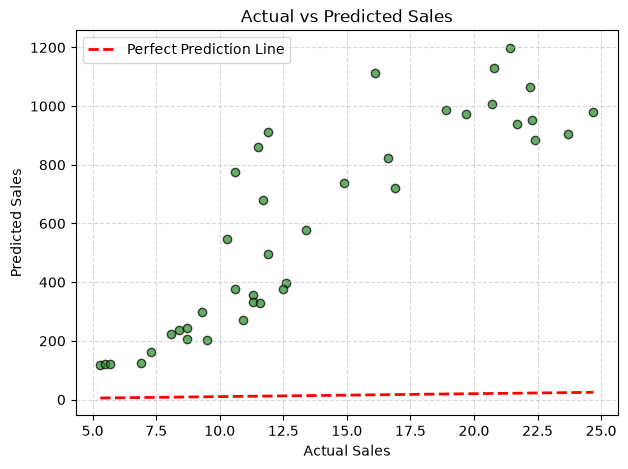

In [11]:
plot_insights(df, y_test, model.predict(X_test))